# Generating simulated data files

This notebook takes files generated by Milo's `toliman_sim` and feeds them into the "on-board" processes, firstly writing the raw camera images, and then running the compression service to generate the downlink-ready `netcdf` files.

In [1]:
from workers.sim_converter import rois_to_acquired_frame
from workers.config import SystemConfig
from workers.camera import AcquiredFrame,CameraMode,XimeaCamera
from workers.acquisition import _get_centre_roi, _data_roi_info
from workers.centroid import (
    CENTRE_ROI_LABEL,
    PointingError,
    compute_pointing_error,
)
from workers.writer import FrameWriter
from workers.compression import compress_session, CompressionParams
from supervisor import CspInterface, SessionCommand, command_to_session_config

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
from typing import Dict, List, Optional

Import simulated data

In [2]:
core_file = "sim_run_0002_data.npy"
lobe_file = "sim_run_0002_lobes.npy"

core = np.load(core_file)
lobes = np.load(lobe_file)

Fake the on-board system config and commands that would run the imaging session

In [3]:
system = SystemConfig.from_file("config.json")
csp = CspInterface(
    node_address=0,
    command_port=10,
    telemetry_port=11,
    obc_address=1
)
command = SessionCommand(
    session_id="sim_run_0002",
    mode=CameraMode.MULTI_ROI,
    frame_rate_hz = 50.0,
    exposure_us=2_500,
    n_frames=100,
    duration_s=None,
    enable_diagnostics=False
)
session = command_to_session_config(command, system)

centre_offset_x, centre_offset_y = system.centre_roi_offset(session)
data_rois = _data_roi_info(session, system)

Set up the writer processes that save raw camera output to disk.

Then, for each simulated image, insert the core and sidelobe images into an AcquiredFrame object using `sim_converter.rois_to_acquired_frame()`.

__Note that because I neither set up exposure time in the simualation correctly, nor worked out which, if any, parts form the `sim_converter.photons_to_adu()` function still need to be included, I have just inserted a fudge factor `scale` to readjust the simulated image photon counts to a value that won't 'saturate'.__

Next, calculate the pointing error from the centre region-of-interest, and send all ROIs to the writers to get saved to disk.

In [4]:
writers: Dict[str, FrameWriter] = {
        label: FrameWriter(
            data_dir=system.data_dir,
            session_id=session.session_id,
            roi_label=label,
            frame_shape=shape,
            buffer_n_frames=system.writer_ring_buffer_n_frames,
            flush_timeout_s=system.writer_flush_timeout_s,
        )
        for label, shape in data_rois.items()
    }

for w in writers.values():
    w.configure_diagnostics(
        session_id=session.session_id,
        log_dir=system.log_dir,
        enable=True,
    )
    w.start()

scale = 0.15

for i,(c,l) in enumerate(zip(core,lobes)):
    roi_photons = {
        "centre": c*scale,
        "top_right": l[1]*scale,
        "bot_right": l[0]*scale,
        "bot_left": l[3]*scale,
        "top_left": l[2]*scale,
    }
    frame = rois_to_acquired_frame(
        roi_photons=roi_photons,
        session=session,
        frame_id=i,
        camera_model="MC203MG-SY-UB",
    )
    
    centre_roi = _get_centre_roi(frame, session)
    pointing: Optional[PointingError] = None

    if centre_roi is not None:
        pointing = compute_pointing_error(
                        centre_roi=centre_roi,
                        roi_offset_x=centre_offset_x,
                        roi_offset_y=centre_offset_y,
                        sensor_width=system.sensor_width,
                        sensor_height=system.sensor_height,
                        timestamp_ns=frame.timestamp_ns,
                        frame_id=frame.frame_id,
                        min_total_intensity=system.centroid_min_total_intensity,
                    )
        for label, writer in writers.items():
            roi_arr = frame.rois.get(label)
            if roi_arr is not None:
                writer.push(roi_arr, frame)

for w in writers.values():
    w.stop()

Set up the parameters for the compression service.

In [5]:
compress_params = CompressionParams(
    session_id = 'sim_run_0002',
    batch_size_n = 10,
    n_stars = 2,
    kernel_path = 'deconvolution_constant.npy',
    sidelobe_offset = 1625,
    strip_width=6,
    corner_roi_labels = ['top_right','bot_right','bot_left','top_left'],
    centre_roi_label = 'centre'
)

Run the compression pipeline

In [6]:
compress_session(system,session,compress_params)

Check the output

In [9]:
import xarray as xr
from pathlib import Path

In [15]:
data_dir = Path(system.data_dir)
filename = compress_params.session_id+'_batch0000.nc'

In [16]:
data = xr.open_dataset(data_dir / filename)

In [17]:
data

<xarray.Dataset>
Dimensions:               (centre_row: 128, centre_col: 128, diff_frame: 9,
                           sl_row: 220, sl_col: 48, frame: 10)
Dimensions without coordinates: centre_row, centre_col, diff_frame, sl_row,
                                sl_col, frame
Data variables:
    centre_reference      (centre_row, centre_col) uint16 ...
    centre_differences    (diff_frame, centre_row, centre_col) float32 ...
    sidelobe_reference    (sl_row, sl_col) uint16 ...
    sidelobe_differences  (diff_frame, sl_row, sl_col) float32 ...
    timestamp_ns          (frame) int64 ...
    frame_id              (frame) int64 ...
    host_time             (frame) timedelta64[ns] ...
    nframes_dropped       (frame) int32 ...
Attributes:
    session_id:     sim_run_0002
    batch_size:     10
    n_stars:        2
    corner_angles:  {'top_left': 45.0, 'top_right': 135.0, 'bot_left': 135.0,...
    strip_width:    6
    conventions:    CF-1.8

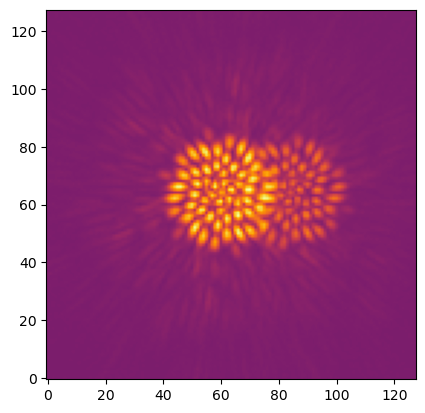

In [20]:
plt.figure()
plt.imshow(data.centre_reference,origin='lower',cmap='inferno', norm=PowerNorm(0.3, vmin=0));

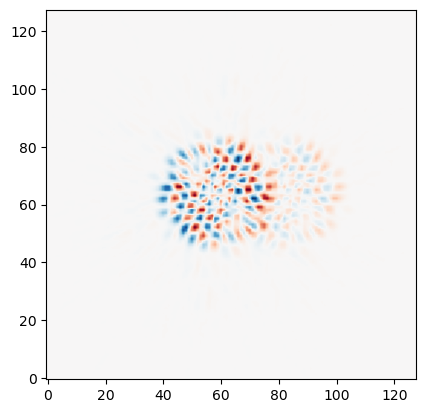

In [25]:
plt.figure()
plt.imshow(data.centre_differences[0],origin='lower',cmap='RdBu');

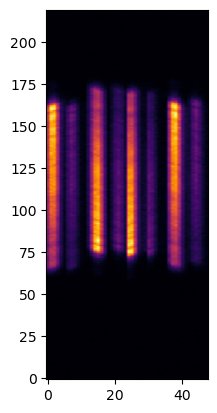

In [30]:
plt.figure()
plt.imshow(data.sidelobe_reference,origin='lower',cmap='inferno', aspect=0.5);

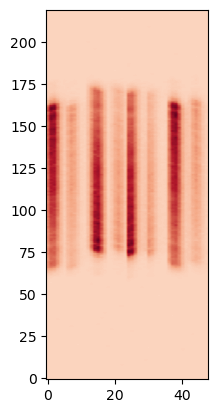

In [41]:
plt.figure()
img = data.sidelobe_differences[0]
max_value = np.max([np.max(img),np.abs(np.min(img))])
plt.imshow(img,origin='lower',cmap='RdBu', aspect=0.5, vmin=-max_value, vmax=max_value);

## Below this point is some scratch space I used to fix some bugs with the cropping

In [9]:
from workers.compression import (
    load_deconvolution_kernel,
    _meta_path, 
    _load_metadata, 
    _load_frame_stack, 
    _corner_roi_shape, 
    _centre_roi_shape,
    _get_corner_offsets
)
from workers.cropping import (
    DEFAULT_STRIP_WIDTH,
    crop_and_merge_corners,
    crop_sidelobe_strip
)
from workers.star_finder import (
    find_stars,
    load_deconvolution_kernel,
    roi_local_to_sensor,
    sensor_to_roi_local,
)

In [10]:
params = compress_params

In [11]:
kernel = load_deconvolution_kernel(params.kernel_path)

In [12]:
meta_path = _meta_path(system.data_dir, params.session_id,
                           params.centre_roi_label)

In [13]:
metadata = _load_metadata(meta_path)

In [14]:
n_frames_total = len(metadata)

In [15]:
centre_stack = _load_frame_stack(
    system.data_dir, params.session_id,
    params.centre_roi_label,
    _centre_roi_shape(system, session),
    n_frames_total,
)
corner_stacks: Dict[str, np.ndarray] = {}
for label in params.corner_roi_labels:
    shape = _corner_roi_shape(system, session, label)
    if shape is None:
        logger.warning("No shape found for corner ROI '%s' - skipping.", label)
        continue
    corner_stacks[label] = _load_frame_stack(
        system.data_dir, params.session_id,
        label, shape, n_frames_total,
    )

In [16]:
# Get ROI offsets for coordinate transforms
centre_offset_x, centre_offset_y = system.centre_roi_offset(session)
corner_offsets = _get_corner_offsets(system, session)

In [17]:
n_batches = (n_frames_total + params.batch_size_n - 1) // params.batch_size_n

In [18]:
batch_idx = 0

In [19]:
start = batch_idx * params.batch_size_n
end   = min(start + params.batch_size_n, n_frames_total)

In [20]:
batch_meta   = metadata[start:end]

In [21]:
batch_centre = centre_stack[start:end]
batch_corners = {
    label: stack[start:end]
    for label, stack in corner_stacks.items()
}

In [22]:
n = len(batch_meta)

In [23]:
sidelobe_strips: List[Optional[np.ndarray]] = []

In [24]:
frame_idx = 0

In [25]:
centre_frame = batch_centre[frame_idx]

In [26]:
stars_local = find_stars(
            centre_frame, kernel,
            n_stars=params.n_stars,
        )

In [27]:
stars_local

{'xs': [61.0, 85.0], 'ys': [65.0, 65.0]}

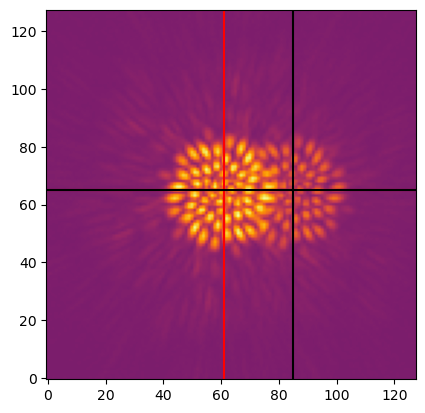

In [28]:
plt.figure()
plt.imshow(centre_frame,origin='lower',cmap='inferno', norm=PowerNorm(0.3, vmin=0))
plt.axvline(61.0,c='r')
plt.axhline(65.0,c='r')

plt.axvline(85.0,c='k')
plt.axhline(65.0,c='k')

In [29]:
# Convert to sensor coordinates
stars_sensor = roi_local_to_sensor(
    stars_local["xs"], stars_local["ys"],
    centre_offset_x, centre_offset_y,
)

In [30]:
stars_sensor

{'xs': [2253.0, 2277.0], 'ys': [2257.0, 2257.0]}

In [31]:
session.rois[0]

RoiDefinition(height=246, offset_y=0, width=246, offset_x=0, label='top_left', is_data=True)

In [32]:
session.rois[2]

RoiDefinition(height=246, offset_y=0, width=246, offset_x=4266, label='top_right', is_data=True)

In [33]:
session.rois[6]

RoiDefinition(height=246, offset_y=4266, width=246, offset_x=0, label='bot_left', is_data=True)

In [34]:
session.rois[8]

RoiDefinition(height=246, offset_y=4266, width=246, offset_x=4266, label='bot_right', is_data=True)

In [35]:
# Transform star positions into each corner ROI's local coordinates
# and extract + merge all sidelobe strips for this frame.
star_positions_per_corner = {
    label: sensor_to_roi_local(
        stars_sensor["xs"], stars_sensor["ys"],
        *corner_offsets.get(label, (0, 0)),
    )
    for label in batch_corners
}

In [36]:
corner_frames = {
    label: stack[frame_idx]
    for label, stack in batch_corners.items()
}

In [37]:
corner_angles=params.corner_angles
width = params.strip_width

In [38]:
angles = corner_angles if corner_angles is not None else DEFAULT_ANGLE_DEGREES

In [39]:
angle_deg = angles.get(label, 45.0)

In [40]:
angle_deg = angles.get('bot_left', 45.0)

In [41]:
angle_deg

135.0

In [42]:
label = 'top_left'


In [43]:
angle_deg = angles.get(label,45.0)

In [44]:
angle_deg

45.0

In [45]:
stars = star_positions_per_corner.get(label, {"xs": [], "ys": []})

In [46]:
star_positions_per_corner

{'top_right': {'xs': [-2013.0, -1989.0], 'ys': [2257.0, 2257.0]},
 'bot_right': {'xs': [-2013.0, -1989.0], 'ys': [-2009.0, -2009.0]},
 'bot_left': {'xs': [2253.0, 2277.0], 'ys': [-2009.0, -2009.0]},
 'top_left': {'xs': [2253.0, 2277.0], 'ys': [2257.0, 2257.0]}}

In [47]:
stars

{'xs': [2253.0, 2277.0], 'ys': [2257.0, 2257.0]}

In [48]:
idx=1
x_s = stars["xs"][idx]
y_s = stars["ys"][idx]

In [49]:
y_s

2257.0

In [52]:
strip = crop_sidelobe_strip(
                corner_frames[label], x_s, y_s,
                angle_degrees = angle_deg,
                width = width
            )

In [53]:
strip.shape

(224, 6)

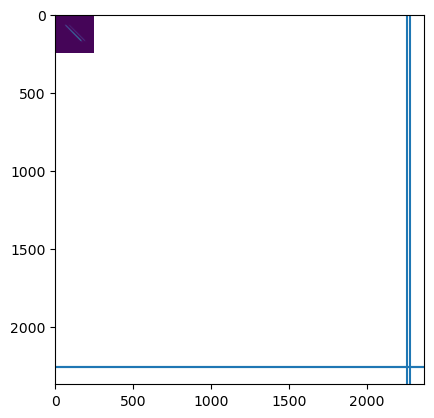

In [54]:
plt.imshow(corner_frames[label])
plt.axvline(stars['xs'][0])
plt.axvline(stars['xs'][1])
plt.axhline(stars['ys'][0])
plt.axhline(stars['ys'][1])

In [55]:
stars

{'xs': [2253.0, 2277.0], 'ys': [2257.0, 2257.0]}

In [56]:
strip = crop_sidelobe_strip(corner_frames['bot_left'], 2253, 2257, angle_degrees = 45.0, width=6)

In [57]:
star_positions_per_corner

{'top_right': {'xs': [-2013.0, -1989.0], 'ys': [2257.0, 2257.0]},
 'bot_right': {'xs': [-2013.0, -1989.0], 'ys': [-2009.0, -2009.0]},
 'bot_left': {'xs': [2253.0, 2277.0], 'ys': [-2009.0, -2009.0]},
 'top_left': {'xs': [2253.0, 2277.0], 'ys': [2257.0, 2257.0]}}

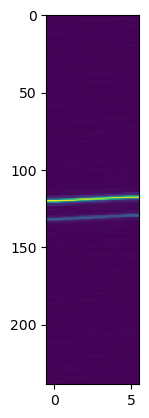

In [58]:
plt.imshow(strip,aspect=0.1)

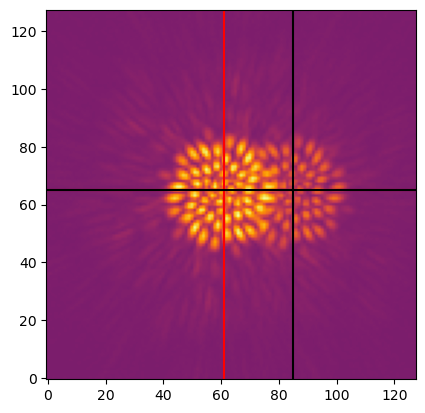

In [59]:
plt.figure()
plt.imshow(centre_frame,origin='lower',cmap='inferno', norm=PowerNorm(0.3, vmin=0))
plt.axvline(61.0,c='r')
plt.axhline(65.0,c='r')

plt.axvline(85.0,c='k')
plt.axhline(65.0,c='k')

In [60]:
merged = crop_and_merge_corners(
            corner_frames,
            star_positions_per_corner,
            corner_angles=params.corner_angles,
            width=params.strip_width,
        )

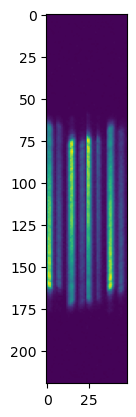

In [63]:
plt.imshow(merged)

In [64]:
compress_session(system,session,compress_params)

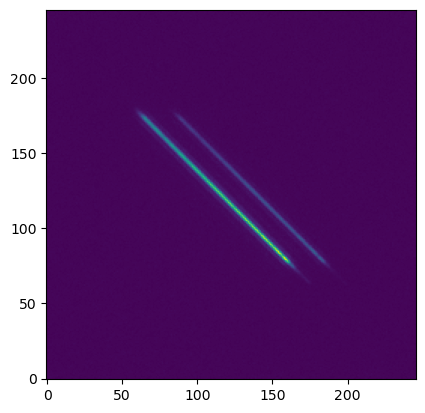

In [16]:
plt.imshow(frame.rois['bot_right'],origin='lower')

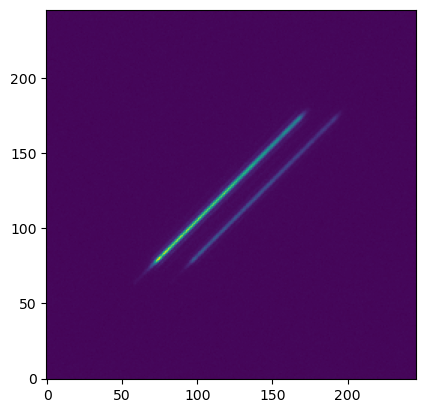

In [42]:
plt.imshow(corner_stacks['top_right'][-1],origin='lower')